In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [17]:
df = pd.read_csv("netflix_titles.csv")
print(df.head())
print("Dataset Shape:", df.shape)
print(df.isnull().sum())

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [2]:
# Remove duplicate rows
df = df.drop_duplicates()

In [3]:
# Remove extra spaces from column names
df.columns = df.columns.str.strip()

In [4]:
# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [5]:
# Fill missing values
columns = ["director", "cast", "country", "rating", "duration"]

for col in columns:
    df[col] = df[col].fillna("Unknown")

In [6]:
# Convert date column
df["date_added"] = pd.to_datetime(
    df["date_added"], errors="coerce"
)

In [7]:
# Create new columns
df["year_added"] = df["date_added"].dt.year
df["duration_value"] = pd.to_numeric(
    df["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

In [8]:
# Save cleaned dataset
df.to_csv("netflix_cleaned.csv", index=False)
print("Data preprocessing completed!")
print(df.isnull().sum())

Data preprocessing completed!
show_id            0
type               0
title              0
director           0
cast               0
country            0
date_added        10
release_year       0
rating             0
duration           0
listed_in          0
description        0
year_added        10
duration_value     3
dtype: int64


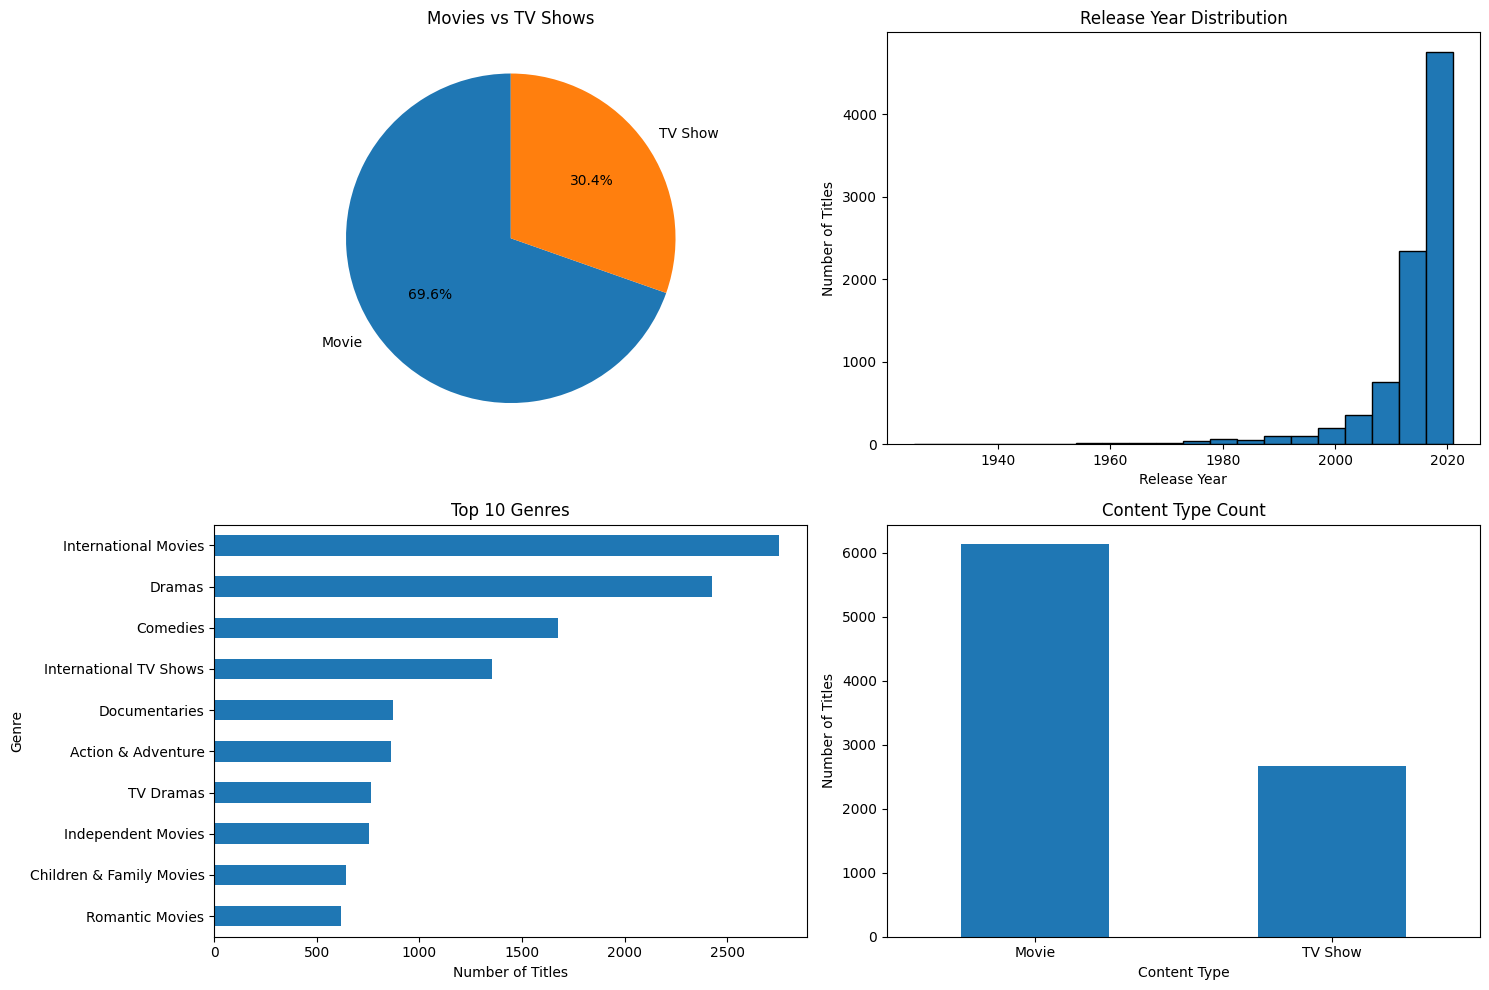

In [11]:
# Dashboard size
plt.figure(figsize=(15, 10))

# 1. Pie chart: Movies and TV Shows
plt.subplot(2, 2, 1)
df["type"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Movies vs TV Shows")
plt.ylabel("")
# 2. Histogram: Release year
plt.subplot(2, 2, 2)
plt.hist(
    df["release_year"].dropna(),
    bins=20,
    edgecolor="black"
)
plt.title("Release Year Distribution")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

# 3. Bar chart: Top 10 genres
plt.subplot(2, 2, 3)
df["listed_in"].str.split(", ").explode().value_counts().head(10).sort_values().plot(
    kind="barh"
)
plt.title("Top 10 Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")

# 4. Bar chart: Movies and TV Shows
plt.subplot(2, 2, 4)
df["type"].value_counts().plot(kind="bar")
plt.title("Content Type Count")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

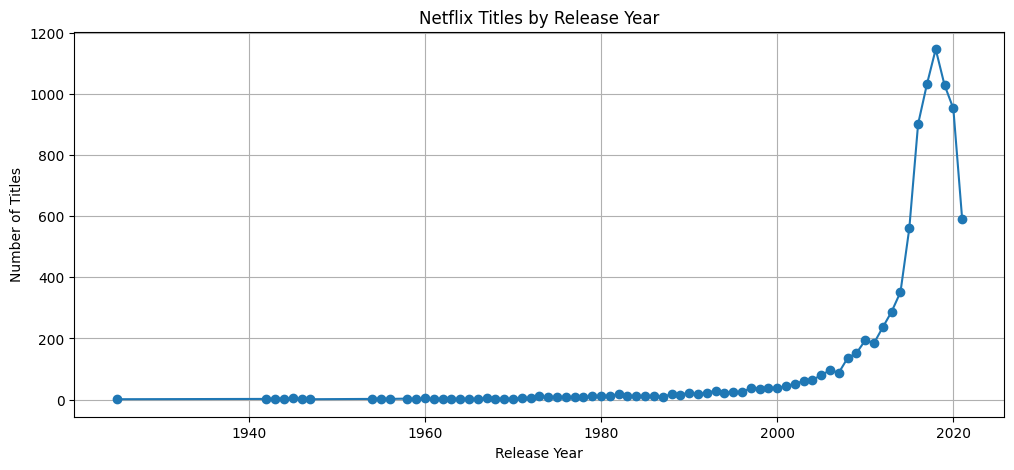

In [14]:
df["release_year"].value_counts().sort_index().plot(
    kind="line",
    figsize=(12, 5),
    marker="o"
)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True)
plt.show()

In [15]:
print("NETFLIX DASHBOARD SUMMARY")
print("-------------------------")
print("Total Titles:", len(df))
print("Total Movies:", (df["type"] == "Movie").sum())
print("Total TV Shows:", (df["type"] == "TV Show").sum())
print("Total Countries:", df["country"].nunique())
print("Total Genres:", df["listed_in"].nunique())
print("Missing Values:", df.isnull().sum().sum())

NETFLIX DASHBOARD SUMMARY
-------------------------
Total Titles: 8807
Total Movies: 6131
Total TV Shows: 2676
Total Countries: 749
Total Genres: 514
Missing Values: 23
